# LungScan in Python

<a href="https://colab.research.google.com/github/AdrianTrill/LungScan/blob/main/notebooks/lungscan.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

This notebook reads lung CT slices with the model and the code of LungScan's server: the backend's preprocessing, the exported ONNX file (29 MB, with int8 weights and the Grad-CAM map computed in the same pass), and the interpretation that turns its output into a read. It runs on the CPU with ONNX Runtime; PyTorch is not needed.

> LungScan is research software, not a medical device. Never use it for diagnosis.

## Setup

In Colab, this clones the repository and installs the backend's requirements. In a clone of the repository, it uses the clone and the environment you started Jupyter from (`pip install -r backend/requirements.txt matplotlib`).

In [1]:
import json
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("LungScan").exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/AdrianTrill/LungScan"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "LungScan/backend/requirements.txt"], check=True)
    ROOT = Path("LungScan").resolve()
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "backend"))

import PIL  # noqa: E402

# Pillow 13 orders the two passes of a resize by the image's shape; the app relies on it.
if int(PIL.__version__.split(".")[0]) < 13:
    raise RuntimeError(f"Pillow {PIL.__version__} is loaded: restart the runtime, then run this cell again")

## The model

The server's `Classifier` loads `model/lungscan.onnx`. If the file is missing, it downloads it from the project's GitHub Pages site with its manifest, and checks its SHA-256. The manifest records where the weights come from and how the file was made.

In [2]:
from app.core.config import settings
from app.services.model import Classifier

classifier = Classifier(settings.model_path, settings.model_url)
classifier.session()
manifest = json.loads(settings.model_path.with_suffix(".json").read_text())
source = manifest["source"]
print(f"{manifest['file']}: {manifest['bytes'] / 1e6:.1f} MB, SHA-256 {manifest['sha256'][:16]}...")
print(f"Weights:  {source['repo']}@{source['revision'][:7]} ({source['license']} license)")
print(f"int8:     {manifest['weights']['int8']}")
print(f"float32:  {manifest['weights']['float32']}")
print(f"Runtime:  {classifier.runtime}")

lungscan.onnx: 29.3 MB, SHA-256 cb4d69814ca4c10f...
Weights:  dorsar/lung-cancer-detection@aa7426d (MIT license)
int8:     42 convolutions, in blocks of 32 values with a float32 scale
float32:  resnet.conv1, resnet.layer1, the biases (BatchNorm folded in), and the head
Runtime:  ONNX Runtime 1.31.1 (server)


## Read the sample slices

The live demo's seven sample studies come from the model's held-out test split. Each read below goes through `analyze_image`, the function the server runs when it analyzes a case, and is compared with the reference read stored in `model/samples/samples.json`.

In [3]:
from app.services.analysis import analyze_image, percent, probability
from app.services.model import LABEL_NAMES, load_rgb

samples = json.loads((ROOT / "model" / "samples" / "samples.json").read_text())
reads = []
print(f"{'case':<10} {'dataset label':<24} {'cancer':>7}  {'read':<8} {'subtype guess':<24} {'regions':>7}  {'vs stored':>9}")
for case in sorted(samples["cases"], key=lambda c: c["id"]):
    image = load_rgb(ROOT / "model" / "samples" / case["image"])
    read = analyze_image(classifier, image, case["id"])
    reads.append((case, image, read))
    change = abs(read.cancer_probability - case["result"]["cancer_probability"])
    print(
        f"{case['id']:<10} {LABEL_NAMES[case['label']]:<24} {probability(read.cancer_probability):>7}  "
        f"{'flagged' if read.flagged else 'clear':<8} {LABEL_NAMES[read.subtype] if read.subtype else '-':<24} "
        f"{len(read.regions):>7}  {change:>9.1e}"
    )

case       dataset label             cancer  read     subtype guess            regions  vs stored
sample-01  Adenocarcinoma             94.5%  flagged  Adenocarcinoma                 1    0.0e+00
sample-02  Squamous cell carcinoma   >99.9%  flagged  Squamous cell carcinoma        1    0.0e+00
sample-03  Adenocarcinoma             85.4%  flagged  Large cell carcinoma           1    0.0e+00
sample-04  Normal                      0.1%  clear    -                              0    0.0e+00
sample-05  Large cell carcinoma       99.7%  flagged  Large cell carcinoma           1    0.0e+00
sample-06  Normal                      0.2%  clear    -                              0    0.0e+00
sample-07  Adenocarcinoma             35.6%  clear    -                              0    0.0e+00


## Where the evidence lies

The heat map is the Grad-CAM map of the log-odds of cancer on the network's last 7×7 feature map, computed inside the ONNX graph. As in the app, it is scaled by the cancer probability and laid over the central crop the network sees, and the circles are the regions the read lists.

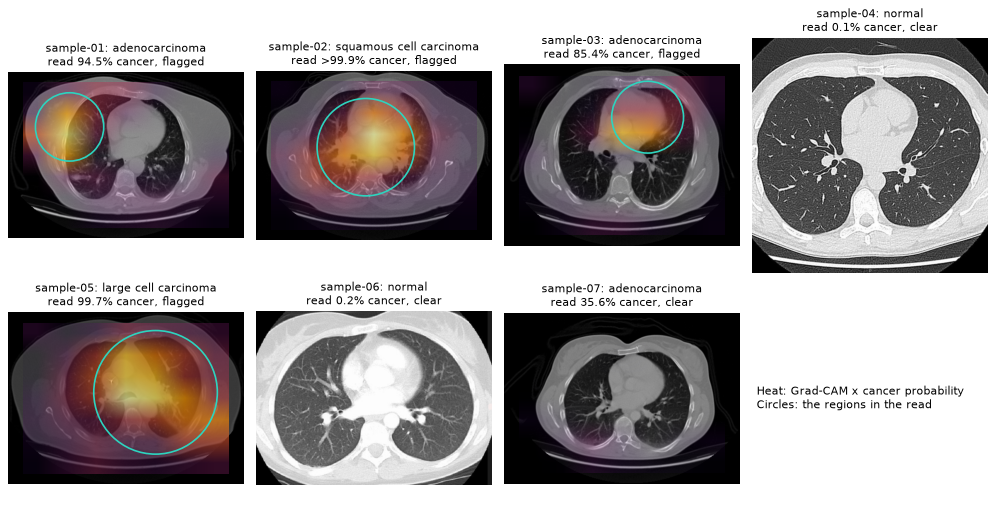

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Circle


def show(ax, image, read, title):
    ax.imshow(image)
    heat = np.array(read.heatmap.values, dtype=np.float32).reshape(read.heatmap.size, -1)
    overlay = plt.cm.inferno(heat)
    overlay[..., 3] = np.clip(heat * 0.9, 0, 0.7)
    box = read.heatmap.box
    extent = (box.x, box.x + box.width, box.y + box.height, box.y)
    ax.imshow(overlay, extent=extent, interpolation="bilinear")
    for region in read.regions:
        ax.add_patch(Circle((region.x, region.y), region.radius, fill=False, color="#2dd4bf", lw=1.5))
    ax.set_xlim(0, image.width)
    ax.set_ylim(image.height, 0)
    ax.set_title(title, fontsize=9.5)
    ax.axis("off")


fig, axes = plt.subplots(2, 4, figsize=(13, 6.6), dpi=80)
for ax, (case, image, read) in zip(axes.flat, reads):
    verdict = "flagged" if read.flagged else "clear"
    show(ax, image, read, f"{case['id']}: {LABEL_NAMES[case['label']].lower()}\nread {probability(read.cancer_probability)} cancer, {verdict}")
axes.flat[-1].axis("off")
axes.flat[-1].text(0.02, 0.5, "Heat: Grad-CAM x cancer probability\nCircles: the regions in the read", fontsize=9.5, va="center")
fig.tight_layout()
plt.show()

## How well it reads

`tools/evaluate.py` measures the app's pipeline on the published test split, after removing the 50 test images that copy training images or each other, and writes `model/evaluation.json`. CI repeats it from a fresh export and requires the same numbers.

In [5]:
evaluation = json.loads((ROOT / "model" / "evaluation.json").read_text())
clean = evaluation["clean_test"]


def counted(m):
    return f"{m['k']} of {m['n']} (95% CI {percent(m['ci95'][0])} to {percent(m['ci95'][1])})"


subtype = clean["subtype_on_cancers"]
int8 = [evaluation["int8_weights"][split] for split in ("validation", "full_test")]
n = sum(s["images"] for s in int8)
print(f"Unique test slices         {clean['images']} of {evaluation['data']['images']['test']}")
print(f"Cancers flagged            {counted(clean['cancer_vs_normal']['sensitivity'])}")
print(f"Normal slices cleared      {counted(clean['cancer_vs_normal']['specificity'])}")
print(f"Four classes               {percent(clean['four_class']['accuracy'])}")
print(f"Subtype, on cancers        {percent(subtype['accuracy'])} (chance is {percent(subtype['chance'])})")
print(
    f"int8 against float32       {sum(s['same_flag'] for s in int8)} of {n} flags and "
    f"{sum(s['same_class'] for s in int8)} of {n} classes the same (validation and test)"
)

Unique test slices         245 of 295
Cancers flagged            237 of 239 (95% CI 97.0% to 99.8%)
Normal slices cleared      6 of 6 (95% CI 61.0% to 100.0%)
Four classes               53.5%
Subtype, on cancers        53.1% (chance is 33.3%)
int8 against float32       367 of 367 flags and 367 of 367 classes the same (validation and test)


## Read a slice of your own

Point `path` at a PNG or JPEG of an axial CT slice (in Colab, upload it with the file browser on the left first). As in the app, the subtype is only a guess: on the deduplicated test split it is right about half the time.

Cancer probability 85.4%: the model reads this slice as cancer. Most likely subtype: Large cell carcinoma (95.0% of the cancer probability), though the model's subtype calls are unreliable. Grad-CAM marks 1 region that raised the cancer score.


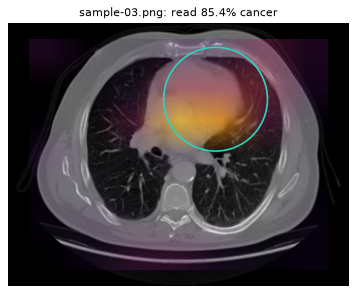

In [6]:
path = ROOT / "model" / "samples" / "images" / "sample-03.png"

image = load_rgb(path)
read = analyze_image(classifier, image, path.stem)
print(read.summary)
fig, ax = plt.subplots(figsize=(5.5, 4.5), dpi=80)
show(ax, image, read, f"{path.name}: read {probability(read.cancer_probability)} cancer")
plt.show()

The [live demo](https://adriantrill.github.io/LungScan/) runs the same file in the browser, and [docs/MODEL.md](../docs/MODEL.md) describes the model, its export, and its evaluation.